# №2. Гистограмма и яркостные преобразования

Изучаем сдвиг яркости, контраст, гамма-коррекцию и автоматическое растяжение диапазона. Гистограмма содержит 256 столбцов: по горизонтали яркость, по вертикали число пикселей.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)

## 1. Гистограмма

Для каждого целого уровня $k$ считаем $h[k]=\#\{(i,j):I_{ij}=k\}$. Сумма столбцов равна количеству пикселей.


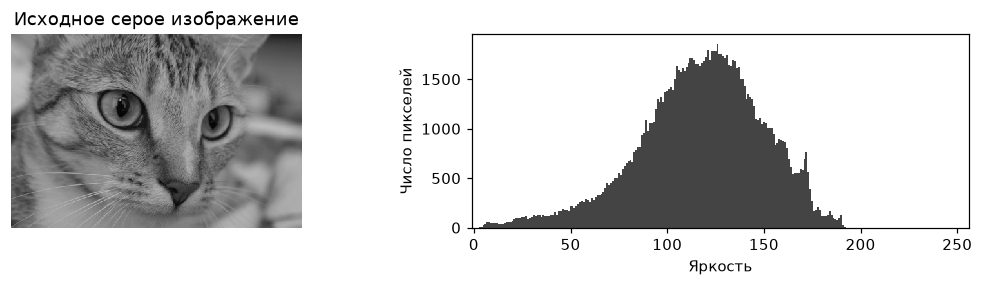

In [3]:
rgb = np.array(Image.open('data/scene.jpg').convert('RGB'))
gray = to_uint8(rgb.astype(float) @ np.array([0.2126, 0.7152, 0.0722]))


def histogram(image):
    return np.bincount(to_uint8(image).ravel(), minlength=256)


def compare_histograms(images, titles):
    fig, axes = plt.subplots(len(images), 2, figsize=(10, 2.7 * len(images)), squeeze=False)
    for row, (image, title) in enumerate(zip(images, titles)):
        axes[row, 0].imshow(image, cmap='gray', vmin=0, vmax=255)
        axes[row, 0].set_title(title)
        axes[row, 0].axis('off')
        axes[row, 1].bar(np.arange(256), histogram(image), width=1, color='#444444')
        axes[row, 1].set(xlim=(-1, 256), xlabel='Яркость', ylabel='Число пикселей')
    fig.tight_layout()
    plt.show()


compare_histograms([gray], ['Исходное серое изображение'])

## 2–3. Добавление и уменьшение яркости

$$I'=\operatorname{clip}(I+b,0,255).$$

Положительный $b$ сдвигает гистограмму вправо, отрицательный — влево. Значения за границами диапазона собираются в столбцах 0 и 255. Вычисляем в `float64`, затем возвращаем 8-битный массив.


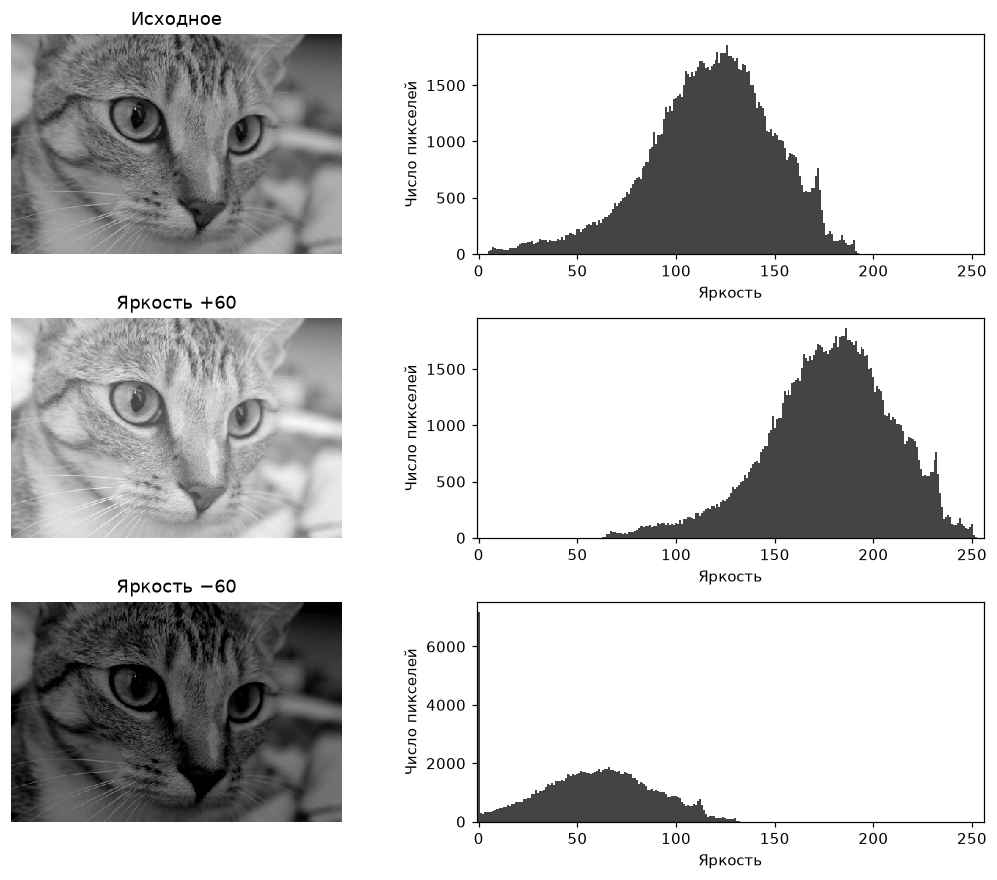

In [4]:
def brightness(image, offset):
    return to_uint8(image.astype(float) + offset)


bright = brightness(gray, 60)
dark = brightness(gray, -60)
compare_histograms([gray, bright, dark], ['Исходное', 'Яркость +60', 'Яркость −60'])

## 4–5. Добавление и уменьшение контраста

$$I'=\operatorname{clip}\bigl(128+c(I-128),0,255\bigr).$$

При $c>1$ значения расходятся от уровня 128. При $0<c<1$ значения сближаются с уровнем 128. При $c=1$ получается исходный массив.


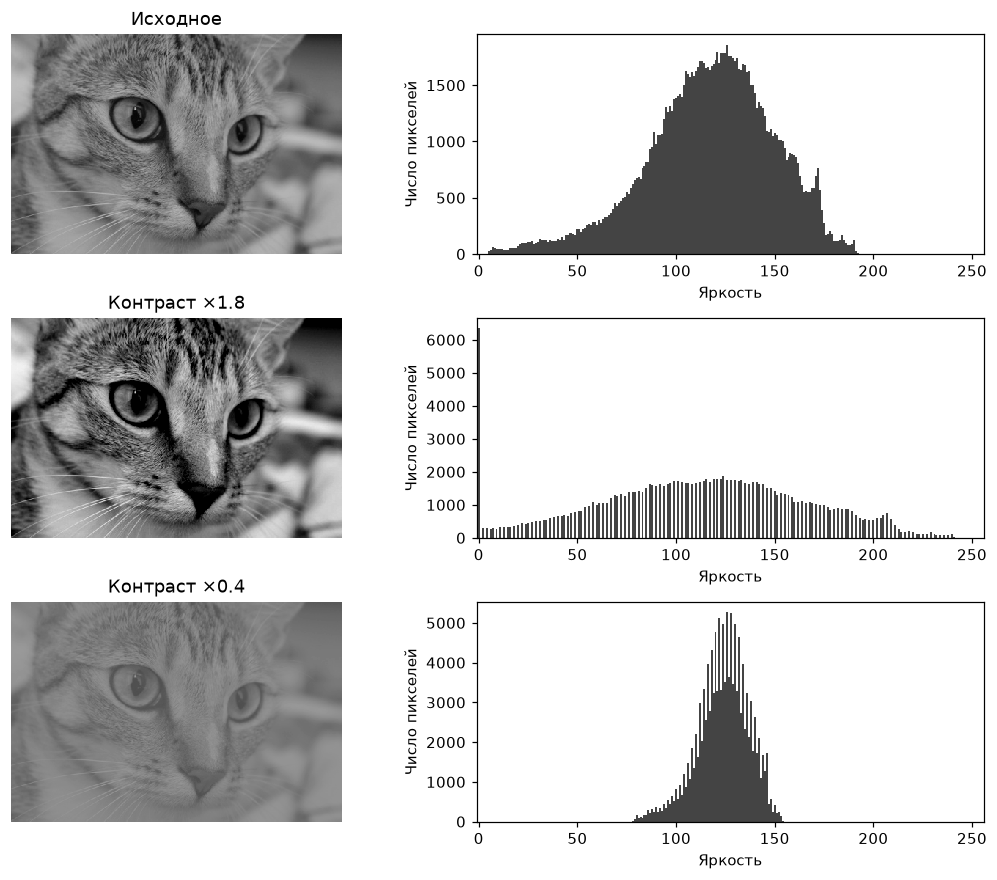

In [5]:
def contrast(image, factor, center=128):
    return to_uint8(center + factor * (image.astype(float) - center))


contrast_up = contrast(gray, 1.8)
contrast_down = contrast(gray, 0.4)
compare_histograms([gray, contrast_up, contrast_down],
                   ['Исходное', 'Контраст ×1.8', 'Контраст ×0.4'])

## 6. Последовательное изменение контраста: «расчёска»

Сначала увеличиваем контраст в 1.8 раза, затем уменьшаем в 1.8 раза. Между шагами сохраняем `uint8`: округление и насыщение становятся частью обработки. Пиксели, собравшиеся на 0 и 255, после второго шага образуют высокие столбцы внутри диапазона.

Для регулярной «расчёски» дополнительно рассматриваем цепочку ×0.4 → ×2.5. Первый шаг склеивает соседние уровни при округлении, второй раздвигает оставшиеся уровни. Равномерный градиент делает структуру гистограммы особенно заметной.


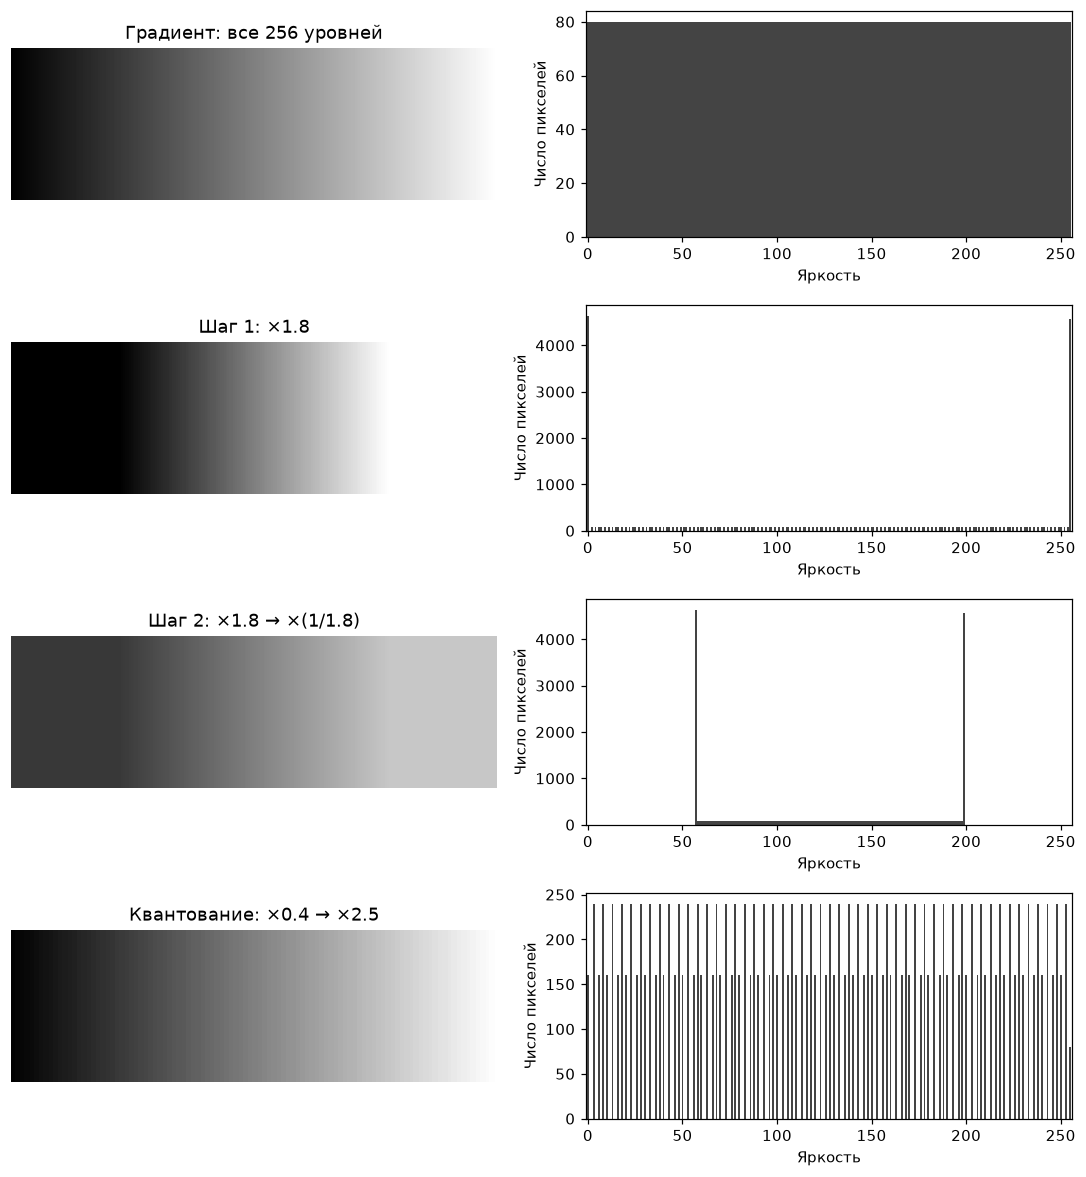

Градиент            : занято 256 уровней; пустых   0
×1.8 → ×(1/1.8)     : занято 143 уровней; пустых 113
×0.4 → ×2.5         : занято 103 уровней; пустых 153


In [6]:
gradient = np.tile(np.arange(256, dtype=np.uint8), (80, 1))
up = contrast(gradient, 1.8)
up_then_down = contrast(up, 1 / 1.8)
down_then_up = contrast(contrast(gradient, 0.4), 2.5)

compare_histograms([gradient, up, up_then_down, down_then_up],
                   ['Градиент: все 256 уровней', 'Шаг 1: ×1.8',
                    'Шаг 2: ×1.8 → ×(1/1.8)', 'Квантование: ×0.4 → ×2.5'])
for name, image in [('Градиент', gradient), ('×1.8 → ×(1/1.8)', up_then_down),
                    ('×0.4 → ×2.5', down_then_up)]:
    used = np.count_nonzero(histogram(image))
    print(f'{name:20s}: занято {used:3d} уровней; пустых {256 - used:3d}')

## 7. Гамма-коррекция

$$I'=255\left(\frac{I}{255}\right)^\gamma.$$

При $\gamma<1$ промежуточные уровни светлеют, при $\gamma>1$ темнеют. Крайние значения 0 и 255 сохраняются. Используем именно показатель $\gamma$ из условия.


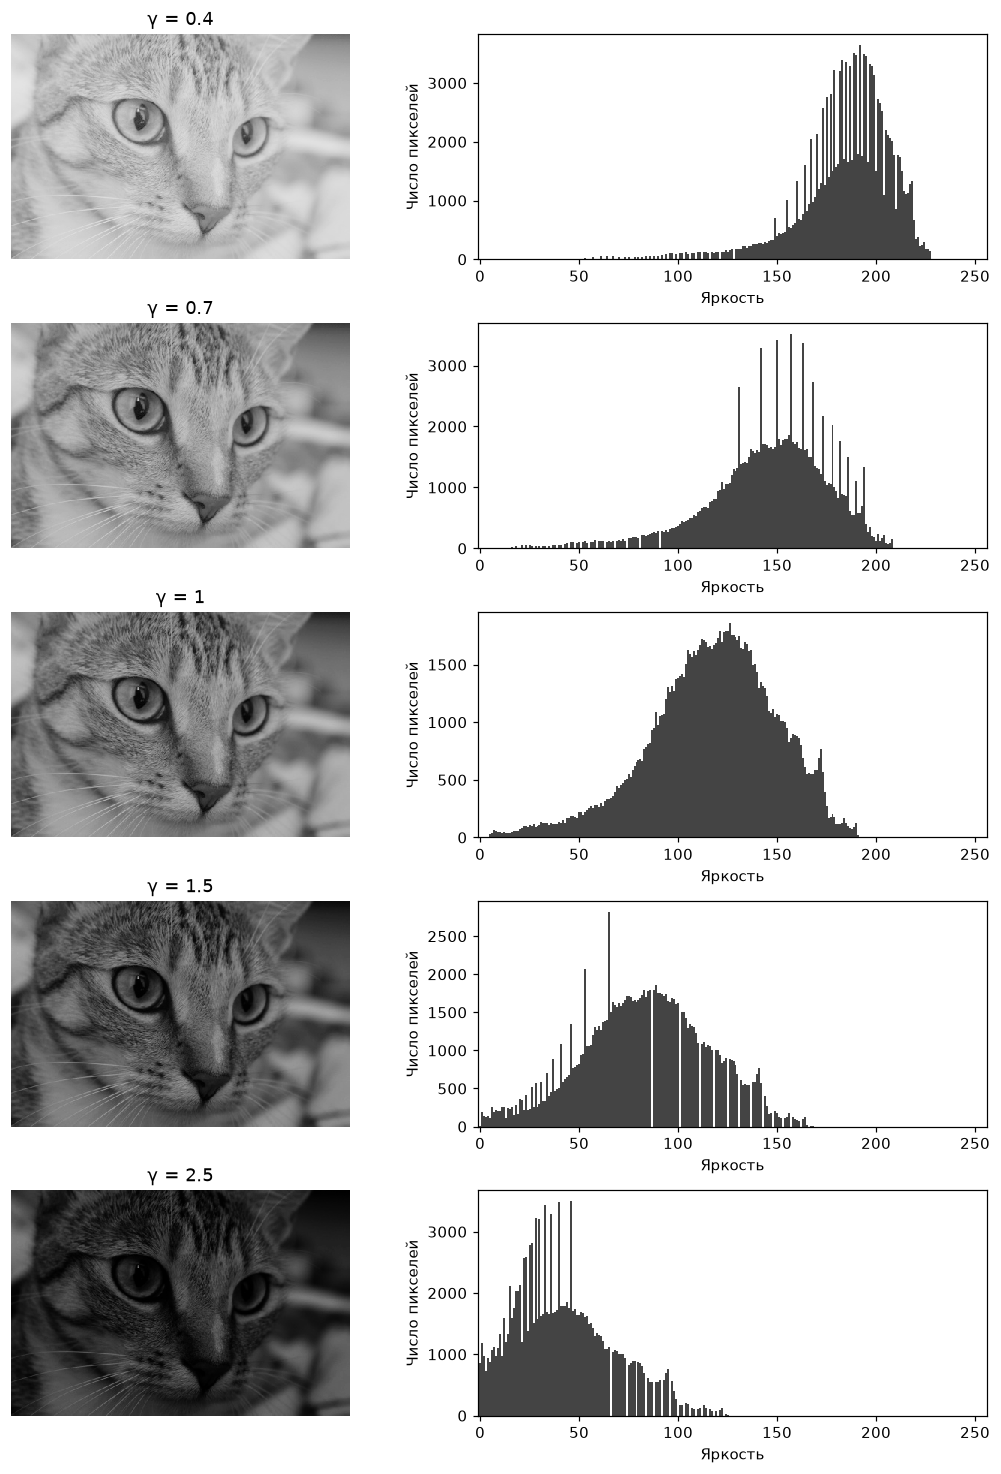

In [7]:
def gamma_correction(image, gamma):
    return to_uint8(255 * (image.astype(float) / 255) ** gamma)


gammas = [0.4, 0.7, 1.0, 1.5, 2.5]
compare_histograms([gamma_correction(gray, gamma) for gamma in gammas],
                   [f'γ = {gamma:g}' for gamma in gammas])

## 8. Автоконтрастирование: множитель

Для тёмного снимка берём $a=255/\max(I)$ и вычисляем $I'=aI$. Максимум становится белым, чёрный уровень сохраняется. Для полностью чёрного массива принимаем $a=1$.


Оптимальный множитель: a = 255/35 = 7.286


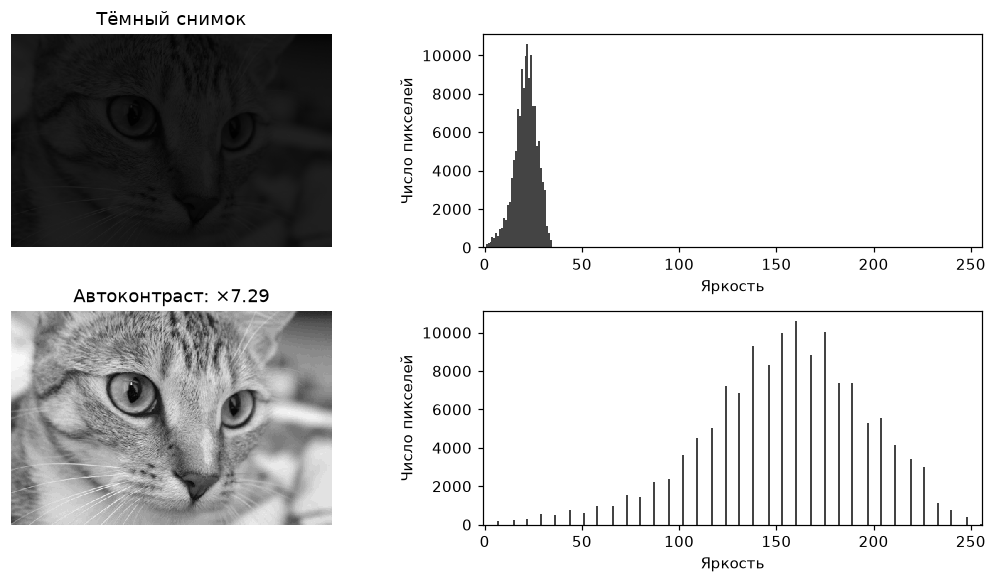

In [8]:
def auto_multiply(image):
    array = image.astype(float)
    maximum = array.max()
    factor = 255 / maximum if maximum > 0 else 1.0
    return to_uint8(array * factor), factor


dark_photo = to_uint8(gray.astype(float) * 0.18)
restored, factor = auto_multiply(dark_photo)
print(f'Оптимальный множитель: a = 255/{dark_photo.max()} = {factor:.3f}')
compare_histograms([dark_photo, restored], ['Тёмный снимок', f'Автоконтраст: ×{factor:.2f}'])

## 9. Автоконтрастирование: слагаемое и полный диапазон

Модель выцветшего скана: $I=90+0.5S$, где $S$ — исходный серый скан. Чёрный текст поднимается к 90, светлая бумага оказывается около 218.

Для белой бумаги берём $b_{white}=255-\max(I)$. Для чёрного текста берём $b_{black}=-\min(I)$. Сдвиг сохраняет размах $\max(I)-\min(I)$ до ограничения диапазона. Одновременное совмещение двух крайних уровней выполняем аффинным преобразованием:

$$a=\frac{255}{\max(I)-\min(I)},\qquad b=-a\min(I),\qquad I'=aI+b.$$


Бумага в белый: b=37.0; текст в чёрный: b=-90.0
Полный диапазон: a=1.992; b=-179.297


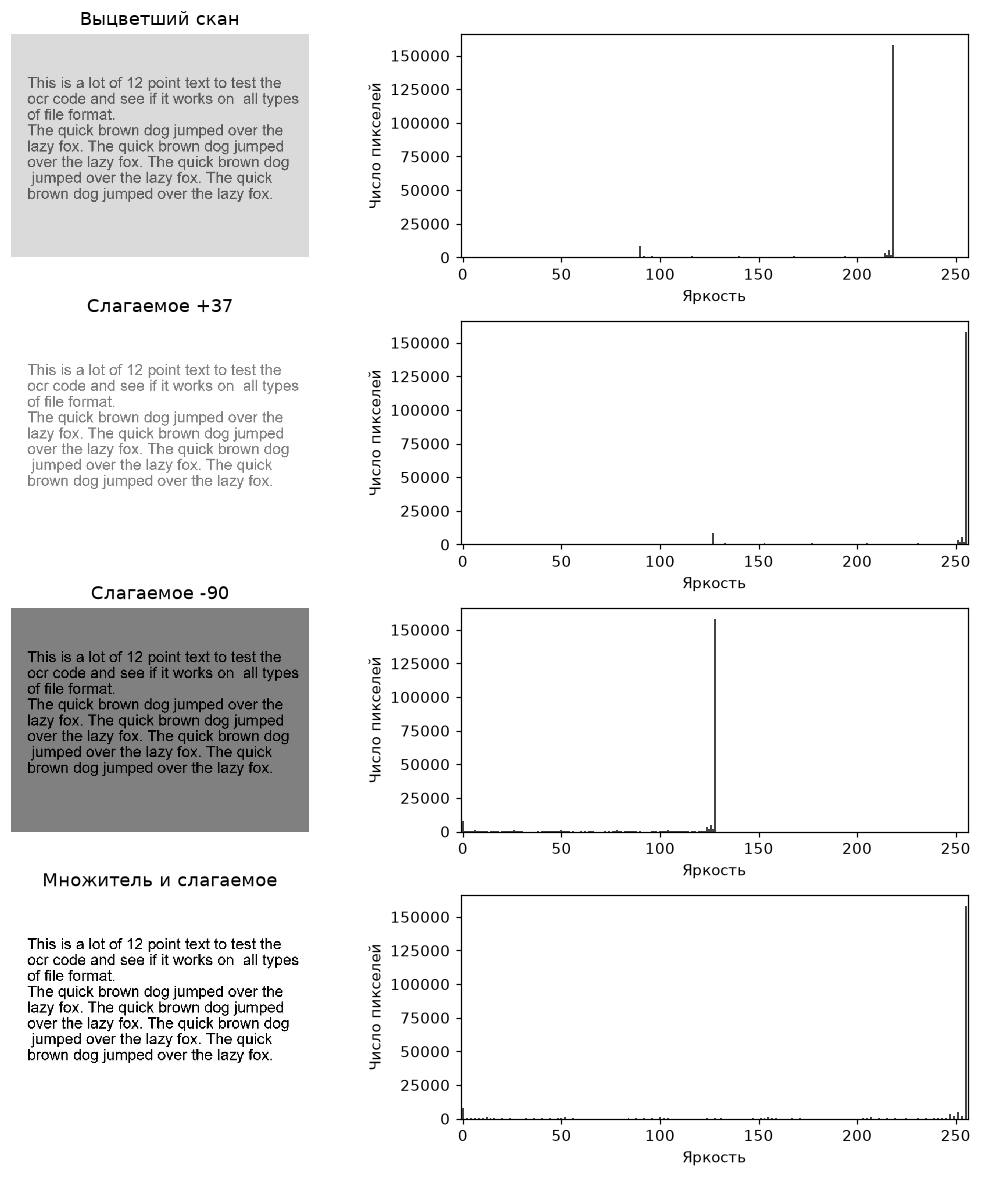

In [9]:
def auto_shift(image, anchor='white'):
    array = image.astype(float)
    offset = 255 - array.max() if anchor == 'white' else -array.min()
    return to_uint8(array + offset), offset


def auto_affine(image):
    array = image.astype(float)
    low, high = array.min(), array.max()
    if high == low:
        return to_uint8(array), 1.0, 0.0
    factor = 255 / (high - low)
    offset = -factor * low
    return to_uint8(factor * array + offset), factor, offset


scan = np.array(Image.open('data/text_scan_1.png').convert('L'))
faded = to_uint8(90 + 0.5 * scan.astype(float))
white, white_shift = auto_shift(faded, 'white')
black, black_shift = auto_shift(faded, 'black')
full_range, auto_factor, auto_offset = auto_affine(faded)
print(f'Бумага в белый: b={white_shift:.1f}; текст в чёрный: b={black_shift:.1f}')
print(f'Полный диапазон: a={auto_factor:.3f}; b={auto_offset:.3f}')
compare_histograms([faded, white, black, full_range],
                   ['Выцветший скан', f'Слагаемое {white_shift:+.0f}',
                    f'Слагаемое {black_shift:+.0f}', 'Множитель и слагаемое'])

## Вывод

Сдвиг яркости переносит гистограмму. Контраст меняет расстояния между уровнями относительно 128. Насыщение объединяет крайние значения, округление объединяет соседние уровни. Повторное растяжение подчёркивает эти потери «расчёской».

Гамма меняет промежуточные уровни, сохраняя крайние. Множитель осветляет тёмный снимок с сохранением нуля. Слагаемое привязывает один выбранный уровень. Пара «множитель + слагаемое» растягивает исходный диапазон до 0–255.
